In [68]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder
import joblib


In [69]:
file_path = r"C:\Users\V\Desktop\PLACEMENT\Projects/Churn/Prediction_Data.xlsx"
sheet_name = 'vw_ChurnData'
data = pd.read_excel(file_path, sheet_name=sheet_name)
print (data.head())

  Customer_ID  Gender  Age Married           State  Number_of_Referrals  \
0   12210-AND    Male   66      No  Andhra Pradesh                    9   
1   12531-AND    Male   56      No  Andhra Pradesh                    1   
2   13500-BIH    Male   51      No           Bihar                    9   
3   14399-MAD  Female   56     Yes  Madhya Pradesh                    8   
4   14622-PUN  Female   49     Yes          Punjab                    9   

   Tenure_in_Months Value_Deal Phone_Service Multiple_Lines  ...  \
0                31        NaN            No             No  ...   
1                12        NaN            No             No  ...   
2                18        NaN            No             No  ...   
3                 9        NaN            No             No  ...   
4                15        NaN            No             No  ...   

    Payment_Method Monthly_Charge Total_Charges Total_Refunds  \
0      Credit Card      34.299999    577.150024           0.0   
1  Bank Wi

In [70]:
data = pd.read_excel(
    file_path,
    sheet_name='vw_ChurnData'
)

print(data['Customer_Status'].value_counts(dropna=False))

Customer_Status
Stayed     4275
Churned    1732
Name: count, dtype: int64


In [71]:
data = data.drop(
    ['Customer_ID', 'Churn_Category', 'Churn_Reason'],
    axis=1
)


data['Customer_Status'] = data['Customer_Status'].astype(str).str.strip()

data = data[
    data['Customer_Status'].isin(['Stayed', 'Churned'])
].copy()

data['Customer_Status'] = data['Customer_Status'].map({
    'Stayed': 0,
    'Churned': 1
})

from sklearn.preprocessing import LabelEncoder

columns_to_encode = [
    'Gender', 'Married', 'State', 'Value_Deal', 'Phone_Service',
    'Multiple_Lines', 'Internet_Service', 'Internet_Type',
    'Online_Security', 'Online_Backup', 'Device_Protection_Plan',
    'Premium_Support', 'Streaming_TV', 'Streaming_Movies',
    'Streaming_Music', 'Unlimited_Data', 'Contract',
    'Paperless_Billing', 'Payment_Method'
]

label_encoders = {}

for column in columns_to_encode:
    le = LabelEncoder()
    data[column] = le.fit_transform(data[column].astype(str))
    label_encoders[column] = le

In [72]:
X = data.drop('Customer_Status', axis=1)
y = data['Customer_Status']

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [73]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


Confusion Matrix:
[[794  61]
 [125 222]]

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.93      0.90       855
           1       0.78      0.64      0.70       347

    accuracy                           0.85      1202
   macro avg       0.82      0.78      0.80      1202
weighted avg       0.84      0.85      0.84      1202



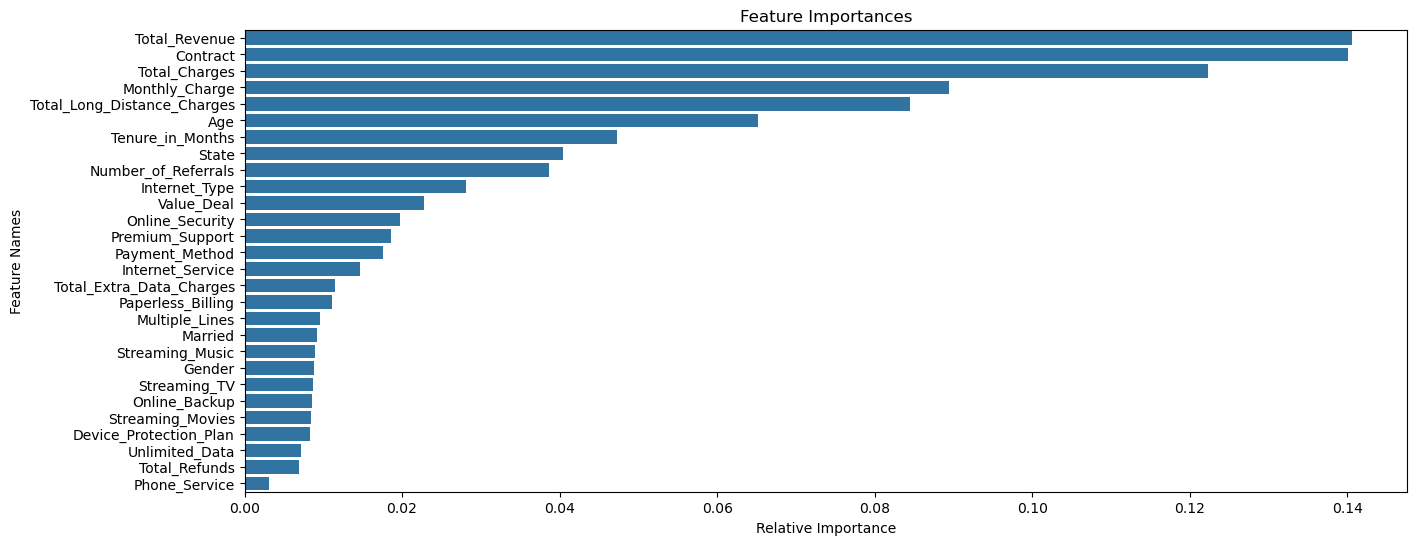

In [74]:
y_pred = rf_model.predict(X_test)

# Evaluate the model
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Feature Selection using Feature Importance
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]

# Plot the feature importances
plt.figure(figsize=(15, 6))
sns.barplot(x=importances[indices], y=X.columns[indices])
plt.title('Feature Importances')
plt.xlabel('Relative Importance')
plt.ylabel('Feature Names')
plt.show()


In [77]:
import pandas as pd

# Load new customer data
file_path = r"C:\Users\V\Desktop\PLACEMENT\Projects\Churn\Prediction_Data.xlsx"

sheet_name = 'vw_JoinData'

new_data = pd.read_excel(file_path, sheet_name=sheet_name)

# Preserve original data
original_data = new_data.copy()

# Retain customer IDs
customer_ids = new_data['Customer_ID'].copy()

# Drop unnecessary columns
new_data = new_data.drop(
    ['Customer_ID', 'Customer_Status', 'Churn_Category', 'Churn_Reason'],
    axis=1,
    errors='ignore'
)

# Handle missing categorical values and unseen categories
for column in new_data.select_dtypes(include=['object']).columns:

    new_data[column] = new_data[column].fillna('Unknown').astype(str)

    known_values = label_encoders[column].classes_

    new_data[column] = new_data[column].apply(
        lambda x: x if x in known_values else known_values[0]
    )

    new_data[column] = label_encoders[column].transform(new_data[column])

# Match training feature columns and order
new_data = new_data[X_train.columns]

# Handle missing numerical values using training medians
new_data = new_data.fillna(X_train.median())

# Make predictions
new_predictions = rf_model.predict(new_data)

# Add predictions to original data
original_data['Customer_Status_Predicted'] = new_predictions

# Filter customers predicted to churn
churn_customers = original_data[
    original_data['Customer_Status_Predicted'] == 1
].copy()

# Save results as Excel
output_path = r"C:\Users\V\Desktop\PLACEMENT\Projects\Churn\Predicted_Churn_Customers.xlsx"

churn_customers.to_excel(output_path, index=False)

print("Prediction completed successfully!")
print("Total customers:", len(original_data))
print("Predicted churn customers:", len(churn_customers))
print("Results saved to:", output_path)


Prediction completed successfully!
Total customers: 411
Predicted churn customers: 384
Results saved to: C:\Users\V\Desktop\PLACEMENT\Projects\Churn\Predicted_Churn_Customers.xlsx


Gender                           0
Age                              0
Married                          0
State                            0
Number_of_Referrals              0
Tenure_in_Months                 0
Value_Deal                     251
Phone_Service                    0
Multiple_Lines                   0
Internet_Service                 0
Internet_Type                  167
Online_Security                  0
Online_Backup                    0
Device_Protection_Plan           0
Premium_Support                  0
Streaming_TV                     0
Streaming_Movies                 0
Streaming_Music                  0
Unlimited_Data                   0
Contract                         0
Paperless_Billing                0
Payment_Method                   0
Monthly_Charge                   0
Total_Charges                    0
Total_Refunds                    0
Total_Extra_Data_Charges         0
Total_Long_Distance_Charges      0
Total_Revenue                    0
dtype: int64
